## Problem Statement
####To investigate whether digital habits such as daily screen time, TikTok usage, number of social media platforms used, sleep duration, and stress level are associated with a person's mood score, and to develop a predictive model that can estimate the mood score based on these factors.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load and understand the data


In [ ]:
df = pd.read_csv('/content/digital_habits_vs_mental_health.csv')
df.head()

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,mood_score
0,10.3,2,5.3,4.4,10,5
1,6.5,5,3.5,6.2,8,8
2,9.1,4,2.8,6.6,7,8
3,6.5,3,2.5,6.5,7,9
4,2.1,3,1.2,7.8,2,10


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   screen_time_hours            100000 non-null  float64
 1   social_media_platforms_used  100000 non-null  int64  
 2   hours_on_TikTok              100000 non-null  float64
 3   sleep_hours                  100000 non-null  float64
 4   stress_level                 100000 non-null  int64  
 5   mood_score                   100000 non-null  int64  
dtypes: float64(3), int64(3)
memory usage: 4.6 MB


In [ ]:
df.shape

(100000, 6)

In [ ]:
df.describe()

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,mood_score
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000
mean,6.003505,2.997820,2.401433,6.988489,6.179590,9.06076
std,1.987073,1.414452,1.079111,1.466330,2.045409,1.27847
min,1.000000,1.000000,0.200000,3.000000,1.000000,2.00000
25%,4.700000,2.000000,1.600000,6.000000,5.000000,8.00000
50%,6.000000,3.000000,2.300000,7.000000,6.000000,10.00000
75%,7.300000,4.000000,3.100000,8.000000,8.000000,10.00000
max,12.000000,5.000000,7.200000,10.000000,10.000000,10.00000


## Data Cleaning

In [ ]:
df.isnull().sum()

,0
screen_time_hours,0
social_media_platforms_used,0
hours_on_TikTok,0
sleep_hours,0
stress_level,0
mood_score,0


In [ ]:
df.duplicated().sum()

np.int64(1865)

In [ ]:
df_clean = df.drop_duplicates().copy()
print("Original dataset shape:", df.shape)
print("After removing duplicates:", df_clean.shape)

Original dataset shape: (100000, 6)
After removing duplicates: (98135, 6)


### Basic outlier checking

In [ ]:
df[df['screen_time_hours'] >= 24]

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,mood_score


In [ ]:
df[df['sleep_hours'] >= 24]

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,mood_score


In [ ]:
df[df["hours_on_TikTok"] >= 24]

,screen_time_hours,social_media_platforms_used,hours_on_TikTok,sleep_hours,stress_level,mood_score


### Checking unique values

In [ ]:
for column in df_clean.columns:
    print(
        f"{column}: "
        f"{df_clean[column].nunique()} unique values"
    )

screen_time_hours: 111 unique values
social_media_platforms_used: 5 unique values
hours_on_TikTok: 71 unique values
sleep_hours: 71 unique values
stress_level: 10 unique values
mood_score: 9 unique values


### Checking Data Ranges

In [ ]:
for column in df_clean.columns:

    print(
        f"{column:35s}"
        f" Min = {df_clean[column].min():.2f},"
        f" Max = {df_clean[column].max():.2f}"
    )

screen_time_hours                   Min = 1.00, Max = 12.00
social_media_platforms_used         Min = 1.00, Max = 5.00
hours_on_TikTok                     Min = 0.20, Max = 7.20
sleep_hours                         Min = 3.00, Max = 10.00
stress_level                        Min = 1.00, Max = 10.00
mood_score                          Min = 2.00, Max = 10.00


In [ ]:
numeric_cols = ['screen_time_hours', 'social_media_platforms_used',
                 'hours_on_TikTok', 'sleep_hours', 'stress_level',
                 'log_transformed_moodscore']

## Univariate Analysis

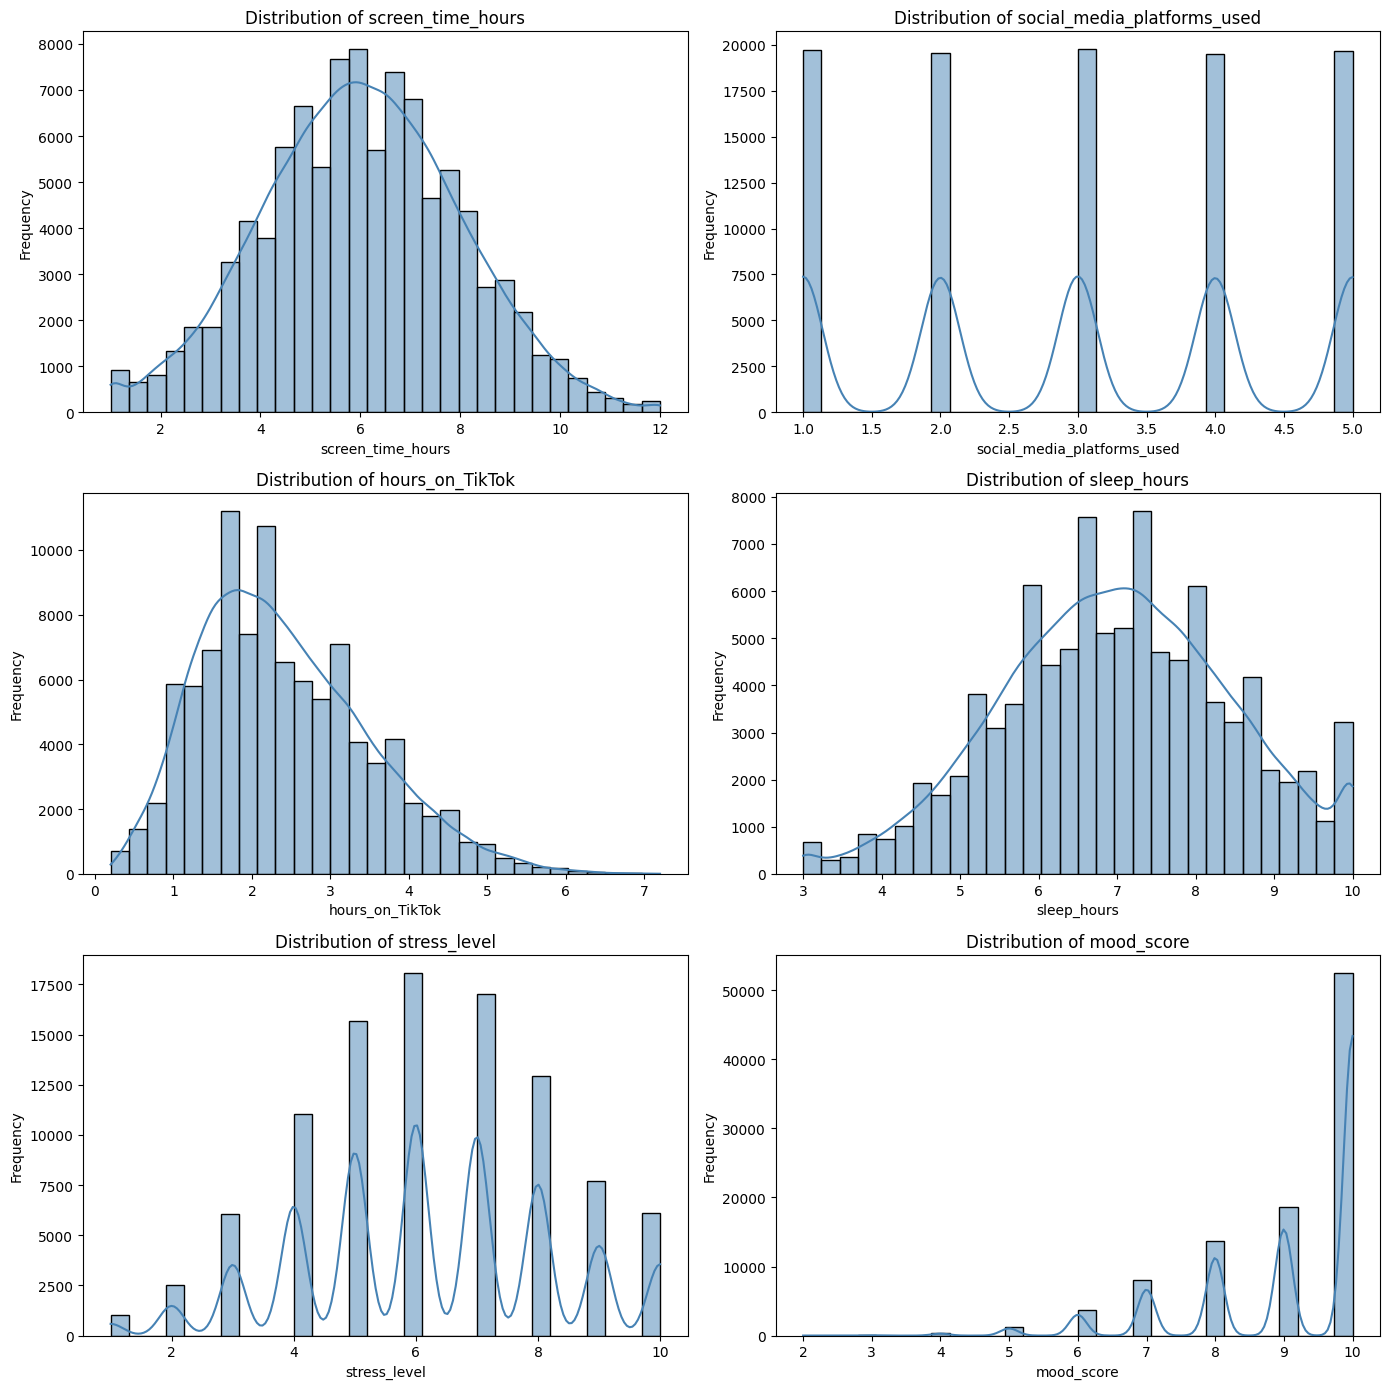

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df_clean.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, col in enumerate(numeric_cols[:6]):
    sns.histplot(df_clean[col], kde=True, bins=30,
                 ax=axes[i], color='steelblue')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

for i in range(len(numeric_cols[:6]), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig('univariate_histograms.png', dpi=150)
plt.show()

### Outlier Detection

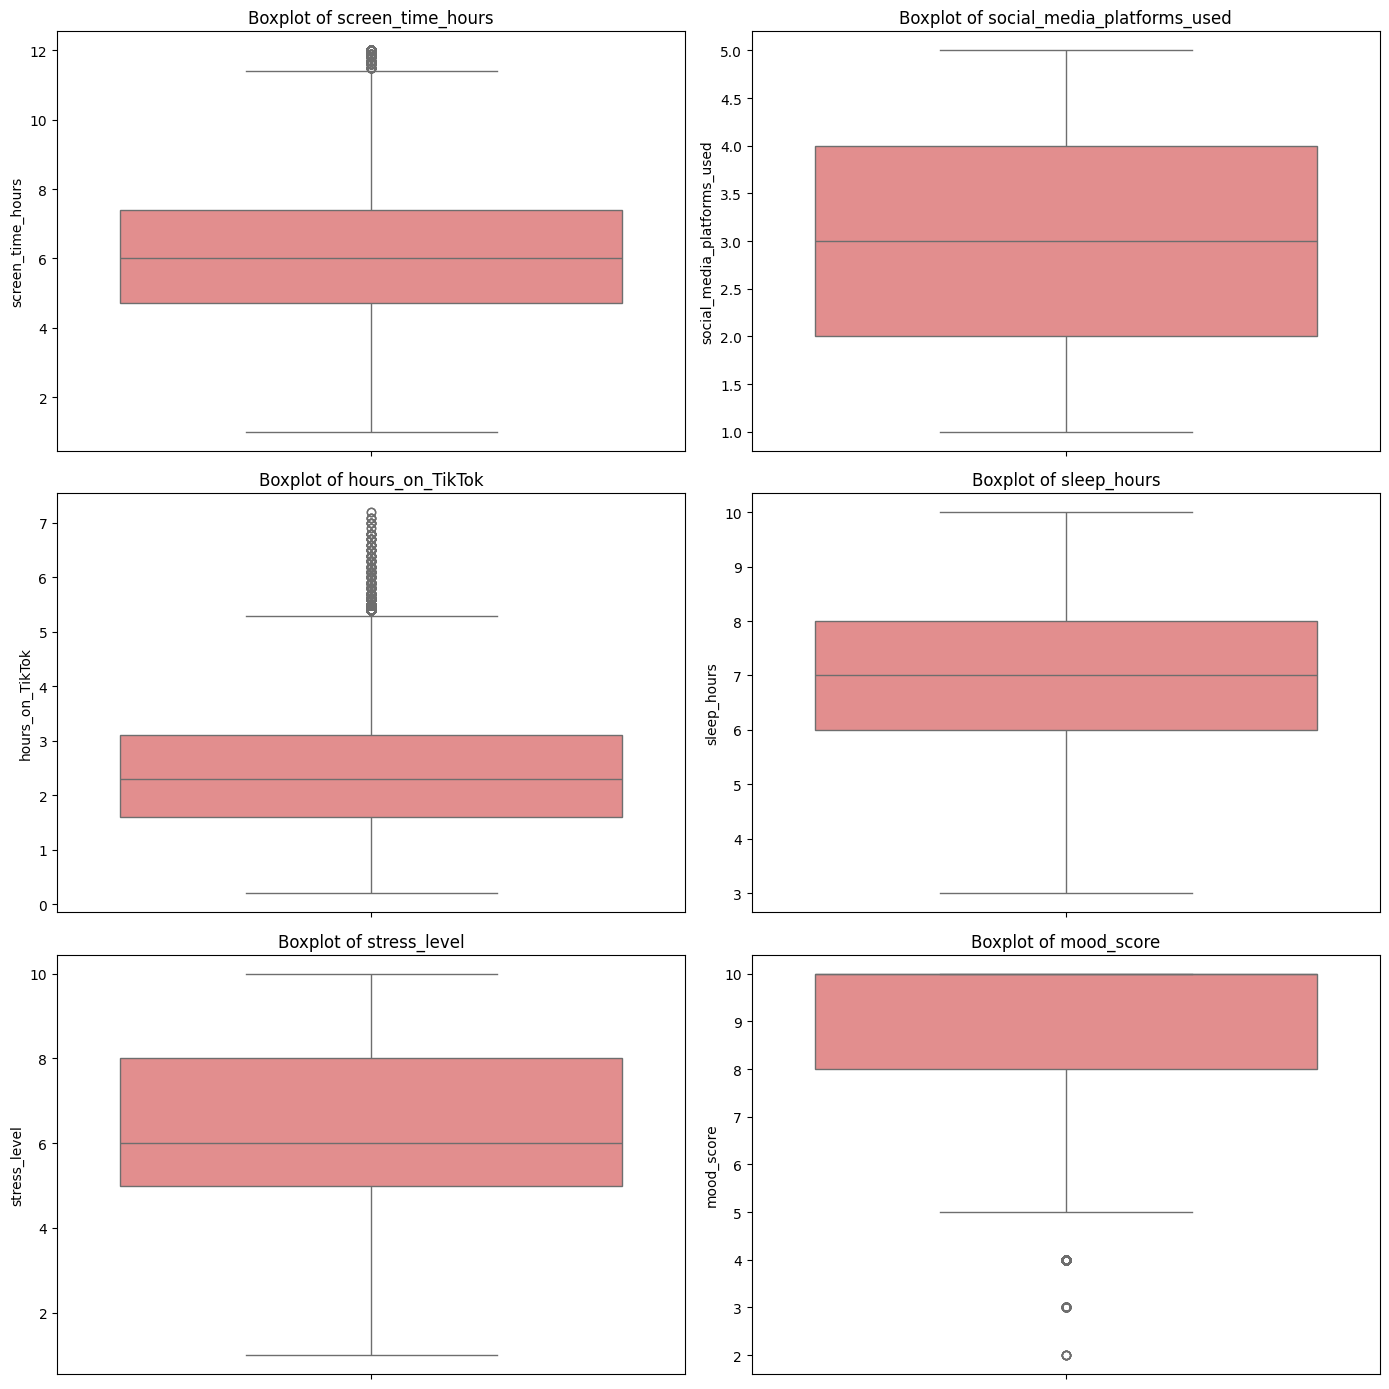

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df_clean.select_dtypes(include='number').columns.tolist()

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for i, col in enumerate(numeric_cols[:6]):
    sns.boxplot(y=df_clean[col], ax=axes[i], color='lightcoral')
    axes[i].set_title(f'Boxplot of {col}')

for i in range(len(numeric_cols[:6]), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.savefig('univariate_boxplots.png', dpi=150)
plt.show()

### Bivariate Analysis

In [ ]:
predictors = ['screen_time_hours', 'social_media_platforms_used',
              'hours_on_TikTok', 'sleep_hours', 'stress_level']
target = 'mood_score'

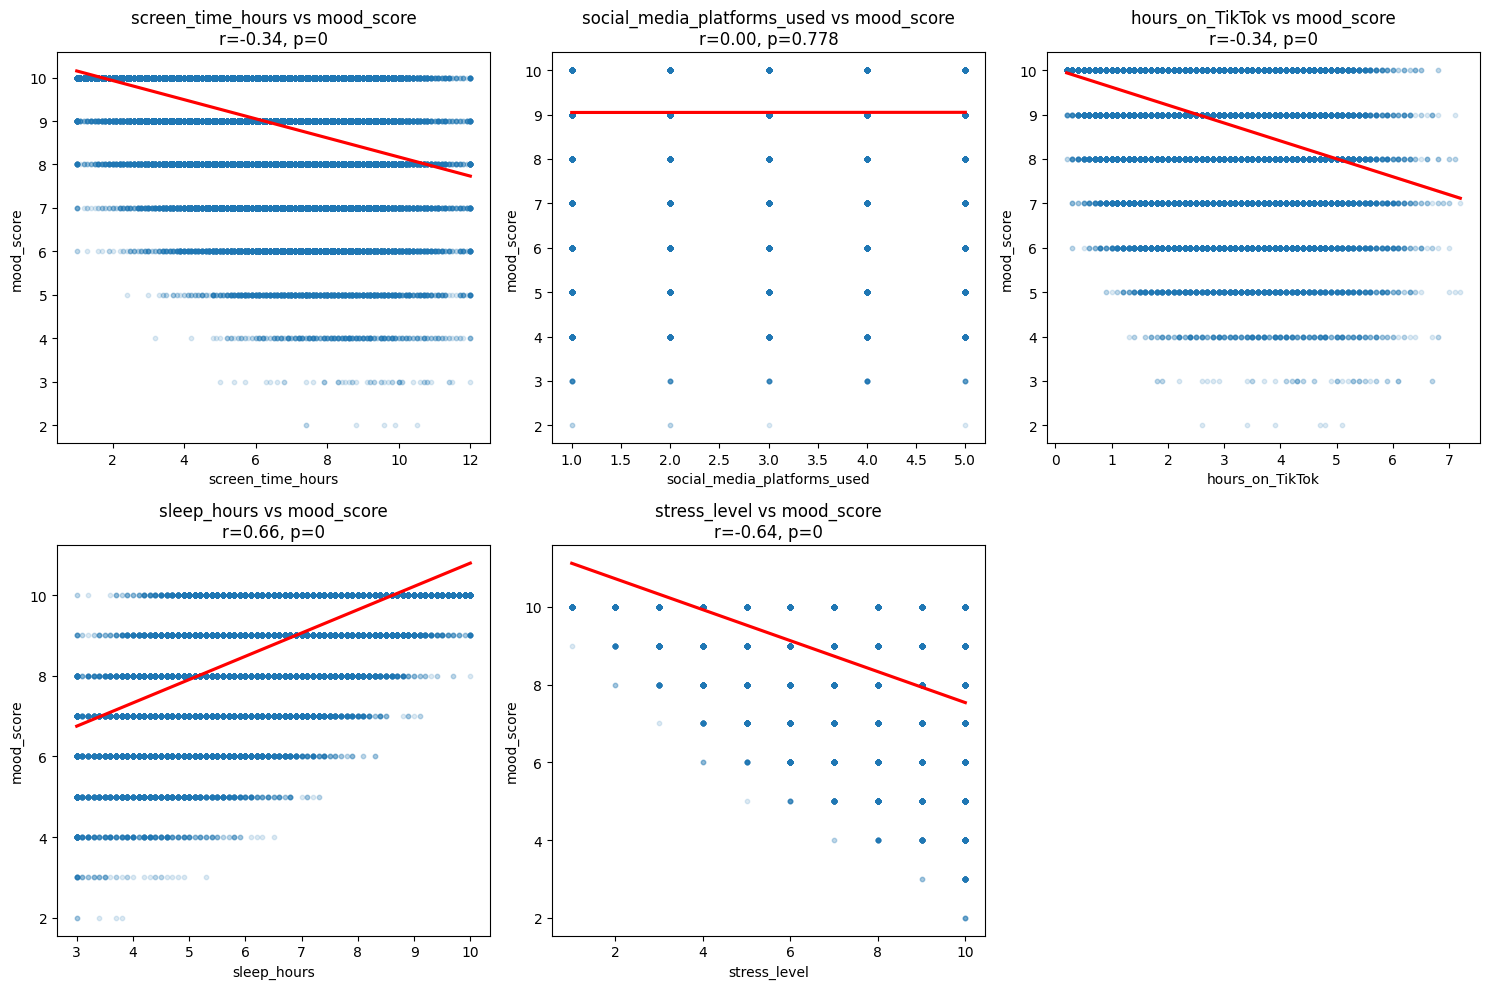

In [ ]:
from scipy.stats import pearsonr
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()
for i, pred in enumerate(predictors):
    sns.regplot(data=df_clean, x=pred, y=target, ax=axes[i],
                scatter_kws={'alpha': 0.15, 's': 10}, line_kws={'color': 'red'})
    r, p = pearsonr(df_clean[pred], df_clean[target])
    axes[i].set_title(f'{pred} vs {target}\nr={r:.2f}, p={p:.3g}')
fig.delaxes(axes[-1])
plt.tight_layout()
plt.savefig('bivariate_scatterplots.png', dpi=150)
plt.show()

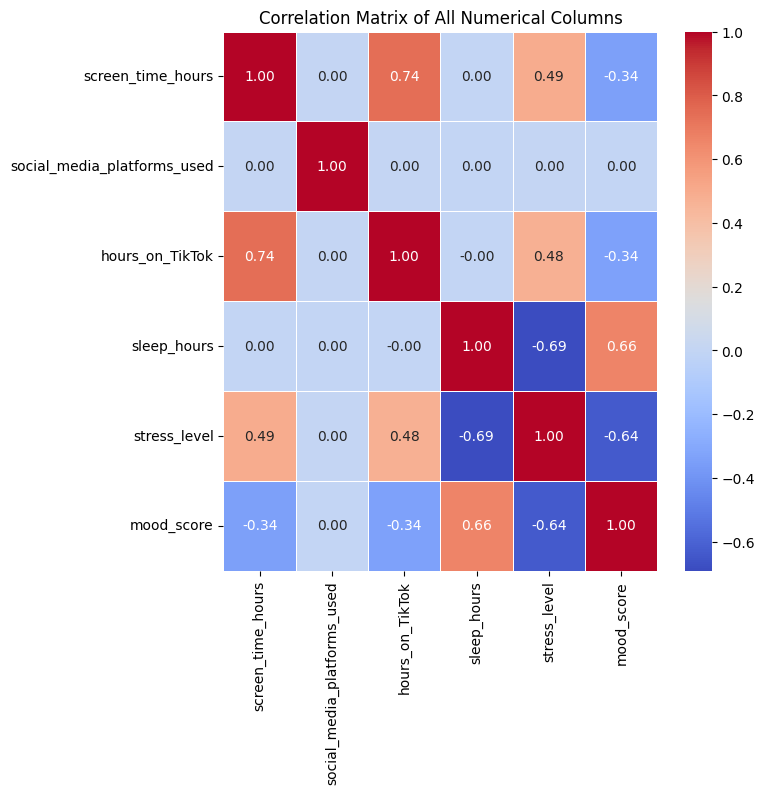

In [ ]:
# Correlation matrix
corr_mat = df_clean.corr(numeric_only=True)
# Heatmap
plt.figure(figsize=(7, 7))
sns.heatmap(corr_mat, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of All Numerical Columns')
plt.show()

In [ ]:
model_features = [
    "screen_time_hours",
    "social_media_platforms_used",
    "hours_on_TikTok",
    "sleep_hours",
    "stress_level"
]

target = "mood_score"

X = df_clean[model_features]

y = df_clean[target]

### Feature Importance - VIF

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# VIF requires a constant term added
X = add_constant(df_clean[model_features])

vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Drop the constant row from the output (not a real predictor)
vif_data = vif_data[vif_data['feature'] != 'const'].reset_index(drop=True)

print(vif_data.sort_values('VIF', ascending=False))

                       feature       VIF
4                 stress_level  3.979835
3                  sleep_hours  2.899616
0            screen_time_hours  2.577023
2              hours_on_TikTok  2.426683
1  social_media_platforms_used  1.000036


## Model Building

### Linear Regression

#### For 80 - 20

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R-squared:", r2)
mape = mean_absolute_percentage_error(y_test, y_pred)
print("MAPE:", mape)

Mean Squared Error: 0.7063650200526013
R-squared: 0.5730531285712768
MAPE: 0.08070316256552815


#### For 75 - 25

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R-squared:", r2)
mape = mean_absolute_percentage_error(y_test, y_pred)
print("MAPE:", mape)

Mean Squared Error: 0.7056899493901742
R-squared: 0.5716783673336274
MAPE: 0.08054284839578982


#### For 70 - 30

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R-squared:", r2)
mape = mean_absolute_percentage_error(y_test, y_pred)
print("MAPE:", mape)

Mean Squared Error: 0.7065005806261727
R-squared: 0.5705870852909507
MAPE: 0.08059973806806495


#### For 65 - 35

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R-squared:", r2)
mape = mean_absolute_percentage_error(y_test, y_pred)
print("MAPE:", mape)

Mean Squared Error: 0.7063964420191946
R-squared: 0.568709598820533
MAPE: 0.08050975935515081


#### For 60 - 40

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print("Mean Squared Error:", mse)
print("R-squared:", r2)
mape = mean_absolute_percentage_error(y_test, y_pred)
print("MAPE:", mape)

Mean Squared Error: 0.7064577071665985
R-squared: 0.569807545559225
MAPE: 0.0805523337785373


### Decision Tree Regressor

#### For 80 - 20

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)
print("Decision Tree Regressor")
print("Mean Squared Error:", mse_dt)
print("R-squared:", r2_dt)
mape = mean_absolute_percentage_error(y_test, y_pred_dt)
print("MAPE:", mape)

Decision Tree Regressor
Mean Squared Error: 1.184783716309166
R-squared: 0.28388342197320915
MAPE: 0.08462774191043923


#### For 75 - 25

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)
print("Decision Tree Regressor")
print("Mean Squared Error:", mse_dt)
print("R-squared:", r2_dt)
mape = mean_absolute_percentage_error(y_test, y_pred_dt)
print("MAPE:", mape)

Decision Tree Regressor
Mean Squared Error: 1.1724749327463928
R-squared: 0.2883611593330667
MAPE: 0.08370570287298093


#### For 70 - 30

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)
print("Decision Tree Regressor")
print("Mean Squared Error:", mse_dt)
print("R-squared:", r2_dt)
mape = mean_absolute_percentage_error(y_test, y_pred_dt)
print("MAPE:", mape)

Decision Tree Regressor
Mean Squared Error: 1.159206359989282
R-squared: 0.2954313196019127
MAPE: 0.08345122448286404


For 65 - 35

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42)
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)
print("Decision Tree Regressor")
print("Mean Squared Error:", mse_dt)
print("R-squared:", r2_dt)
mape = mean_absolute_percentage_error(y_test, y_pred_dt)
print("MAPE:", mape)

Decision Tree Regressor
Mean Squared Error: 1.1810367415861185
R-squared: 0.27891792796922554
MAPE: 0.08388649508947633


#### For 60 - 40

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
dt = DecisionTreeRegressor(random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
mse_dt = mean_squared_error(y_test, y_pred_dt)
r2_dt = r2_score(y_test, y_pred_dt)
print("Decision Tree Regressor")
print("Mean Squared Error:", mse_dt)
print("R-squared:", r2_dt)
mape = mean_absolute_percentage_error(y_test, y_pred_dt)
print("MAPE:", mape)

Decision Tree Regressor
Mean Squared Error: 1.1755744637489174
R-squared: 0.2841421944898057
MAPE: 0.08382569039572148


### XGBoost Regressor

#### For 80 - 20

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)
print("XGBoost Regressor")
print("Mean Squared Error:", mse_xgb)
print("R-squared:", r2_xgb)
mape = mean_absolute_percentage_error(y_test, y_pred_xgb)
print("MAPE:", mape)

XGBoost Regressor
Mean Squared Error: 0.5512393116950989
R-squared: 0.666815459728241
MAPE: 0.06397949904203415


#### For 75 - 25

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)
print("XGBoost Regressor")
print("Mean Squared Error:", mse_xgb)
print("R-squared:", r2_xgb)
mape = mean_absolute_percentage_error(y_test, y_pred_xgb)
print("MAPE:", mape)

XGBoost Regressor
Mean Squared Error: 0.5502772331237793
R-squared: 0.6660068035125732
MAPE: 0.06372987478971481


#### For 70 - 30

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)
print("XGBoost Regressor")
print("Mean Squared Error:", mse_xgb)
print("R-squared:", r2_xgb)
mape = mean_absolute_percentage_error(y_test, y_pred_xgb)
print("MAPE:", mape)

XGBoost Regressor
Mean Squared Error: 0.5542479157447815
R-squared: 0.6631266474723816
MAPE: 0.06389632076025009


#### For 65 - 35

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42)
xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)
print("XGBoost Regressor")
print("Mean Squared Error:", mse_xgb)
print("R-squared:", r2_xgb)
mape = mean_absolute_percentage_error(y_test, y_pred_xgb)
print("MAPE:", mape)

XGBoost Regressor
Mean Squared Error: 0.5557039976119995
R-squared: 0.6607149243354797
MAPE: 0.0639367327094078


#### For 60 - 40

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
r2_xgb = r2_score(y_test, y_pred_xgb)
print("XGBoost Regressor")
print("Mean Squared Error:", mse_xgb)
print("R-squared:", r2_xgb)
mape = mean_absolute_percentage_error(y_test, y_pred_xgb)
print("MAPE:", mape)

XGBoost Regressor
Mean Squared Error: 0.5574463605880737
R-squared: 0.6605470180511475
MAPE: 0.0640483871102333


### KNN Regressor

#### For 80 - 20 split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
knn = KNeighborsRegressor()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)
print("KNN Regressor")
print("Mean Squared Error:", mse_knn)
print("R-squared:", r2_knn)
mape = mean_absolute_percentage_error(y_test, y_pred_knn)
print("MAPE:", mape)

KNN Regressor
Mean Squared Error: 0.6587374535079227
R-squared: 0.6018405684256734
MAPE: 0.06834380239077849


#### For 75 - 25 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
knn = KNeighborsRegressor()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)
print("KNN Regressor")
print("Mean Squared Error:", mse_knn)
print("R-squared:", r2_knn)
mape = mean_absolute_percentage_error(y_test, y_pred_knn)
print("MAPE:", mape)

KNN Regressor
Mean Squared Error: 0.6597244640091302
R-squared: 0.5995773217706639
MAPE: 0.06825333744812834


#### For 70 - 30 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
knn = KNeighborsRegressor()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)
print("KNN Regressor")
print("Mean Squared Error:", mse_knn)
print("R-squared:", r2_knn)
mape = mean_absolute_percentage_error(y_test, y_pred_knn)
print("MAPE:", mape)

KNN Regressor
Mean Squared Error: 0.6666363234944465
R-squared: 0.5948166858278301
MAPE: 0.06857856687278242


#### For 65 - 35 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42)
knn = KNeighborsRegressor()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)
print("KNN Regressor")
print("Mean Squared Error:", mse_knn)
print("R-squared:", r2_knn)
mape = mean_absolute_percentage_error(y_test, y_pred_knn)
print("MAPE:", mape)

KNN Regressor
Mean Squared Error: 0.6670664958658437
R-squared: 0.5927225004234329
MAPE: 0.06846999016601323


#### For 60 - 40 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
knn = KNeighborsRegressor()
knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)
print("KNN Regressor")
print("Mean Squared Error:", mse_knn)
print("R-squared:", r2_knn)
mape = mean_absolute_percentage_error(y_test, y_pred_knn)
print("MAPE:", mape)

KNN Regressor
Mean Squared Error: 0.6656972537830539
R-squared: 0.5946283371045717
MAPE: 0.068412746936719


### For SVR

In [ ]:
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split

#### For 80 - 20 split

In [ ]:
svr = SVR()
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)
mse_svr = mean_squared_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)
print("SVR")
print("Mean Squared Error:", mse_svr)
print("R-squared:", r2_svr)
mape = mean_absolute_percentage_error(y_test, y_pred_svr)
print("MAPE:", mape)

SVR
Mean Squared Error: 0.564687015263946
R-squared: 0.6561378117572927
MAPE: 0.06277684689189997


#### For 75 - 25 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
svr = SVR()
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)
mse_svr = mean_squared_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)
print("SVR")
print("Mean Squared Error:", mse_svr)
print("R-squared:", r2_svr)
mape = mean_absolute_percentage_error(y_test, y_pred_svr)
print("MAPE:", mape)

SVR
Mean Squared Error: 0.5597705388759654
R-squared: 0.6602447982473321
MAPE: 0.06254150404123353


#### For 70 - 30 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
svr = SVR()
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)
mse_svr = mean_squared_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)
print("SVR")
print("Mean Squared Error:", mse_svr)
print("R-squared:", r2_svr)
mape = mean_absolute_percentage_error(y_test, y_pred_svr)
print("MAPE:", mape)

SVR
Mean Squared Error: 0.5629357254768054
R-squared: 0.6578461825797781
MAPE: 0.06266725423966105


#### For 65 - 35 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42)
svr = SVR()
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)
mse_svr = mean_squared_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)
print("SVR")
print("Mean Squared Error:", mse_svr)
print("R-squared:", r2_svr)
mape = mean_absolute_percentage_error(y_test, y_pred_svr)
print("MAPE:", mape)

SVR
Mean Squared Error: 0.5641473170626532
R-squared: 0.6555598128371373
MAPE: 0.06270922672444017


#### For 60 - 40 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
svr = SVR()
svr.fit(X_train, y_train)
y_pred_svr = svr.predict(X_test)
mse_svr = mean_squared_error(y_test, y_pred_svr)
r2_svr = r2_score(y_test, y_pred_svr)
print("SVR")
print("Mean Squared Error:", mse_svr)
print("R-squared:", r2_svr)
mape = mean_absolute_percentage_error(y_test, y_pred_svr)
print("MAPE:", mape)

SVR
Mean Squared Error: 0.564687015263946
R-squared: 0.6561378117572927
MAPE: 0.06277684689189997


### Random Forest Regressor

#### For 80 - 20 split

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
print("Random Forest Regressor")
print("Mean Squared Error:", mse_rf)
print("R-squared:", r2_rf)
mape = mean_absolute_percentage_error(y_test, y_pred_rf)
print("MAPE:", mape)

Random Forest Regressor
Mean Squared Error: 0.6376361253823354
R-squared: 0.6145948042250897
MAPE: 0.06825105725689372


#### For 75 - 25 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
print("Random Forest Regressor")
print("Mean Squared Error:", mse_rf)
print("R-squared:", r2_rf)
mape = mean_absolute_percentage_error(y_test, y_pred_rf)
print("MAPE:", mape)

Random Forest Regressor
Mean Squared Error: 0.6320489068608521
R-squared: 0.616375123458141
MAPE: 0.06784100283344273


#### For 70 - 30 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
print("Random Forest Regressor")
print("Mean Squared Error:", mse_rf)
print("R-squared:", r2_rf)
mape = mean_absolute_percentage_error(y_test, y_pred_rf)
print("MAPE:", mape)

Random Forest Regressor
Mean Squared Error: 0.6347875727343288
R-squared: 0.6141744404691962
MAPE: 0.06793214061615423


#### For 65 - 35 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42)
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
print("Random Forest Regressor")
print("Mean Squared Error:", mse_rf)
print("R-squared:", r2_rf)
mape = mean_absolute_percentage_error(y_test, y_pred_rf)
print("MAPE:", mape)

Random Forest Regressor
Mean Squared Error: 0.6352691195822858
R-squared: 0.6121363909217907
MAPE: 0.06788506353930461


#### For 60 - 40 split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)
print("Random Forest Regressor")
print("Mean Squared Error:", mse_rf)
print("R-squared:", r2_rf)
mape = mean_absolute_percentage_error(y_test, y_pred_rf)
print("MAPE:", mape)

Random Forest Regressor
Mean Squared Error: 0.6383335285756477
R-squared: 0.6112912852049327
MAPE: 0.06814425959976692


#### ANN

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import BatchNormalization
import warnings
warnings.filterwarnings("ignore")

##### For 80 - 20 split

#### Architecture 1: 64 -> 32 -> 1

In [ ]:
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(X, y, test_size=0.20, random_state=42)

scaler_80 = StandardScaler()
X_train_80_scaled = scaler_80.fit_transform(X_train_80)
X_test_20_scaled = scaler_80.transform(X_test_20)

model_80 = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_80_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model_80.compile(optimizer='adam', loss='mse')

history_80 = model_80.fit(X_train_80_scaled, y_train_80,
                          validation_data=(X_test_20_scaled, y_test_20),
                          epochs=1000, batch_size=32, verbose=0)

y_pred_20 = model_80.predict(X_test_20_scaled)
print(f"80/20 MSE: {mean_squared_error(y_test_20, y_pred_20):.4f}")
print(f"80/20 R-squared: {r2_score(y_test_20, y_pred_20):.4f}")

614/614 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
80/20 MSE: 0.1160
80/20 R-squared: 0.6498


614/614 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


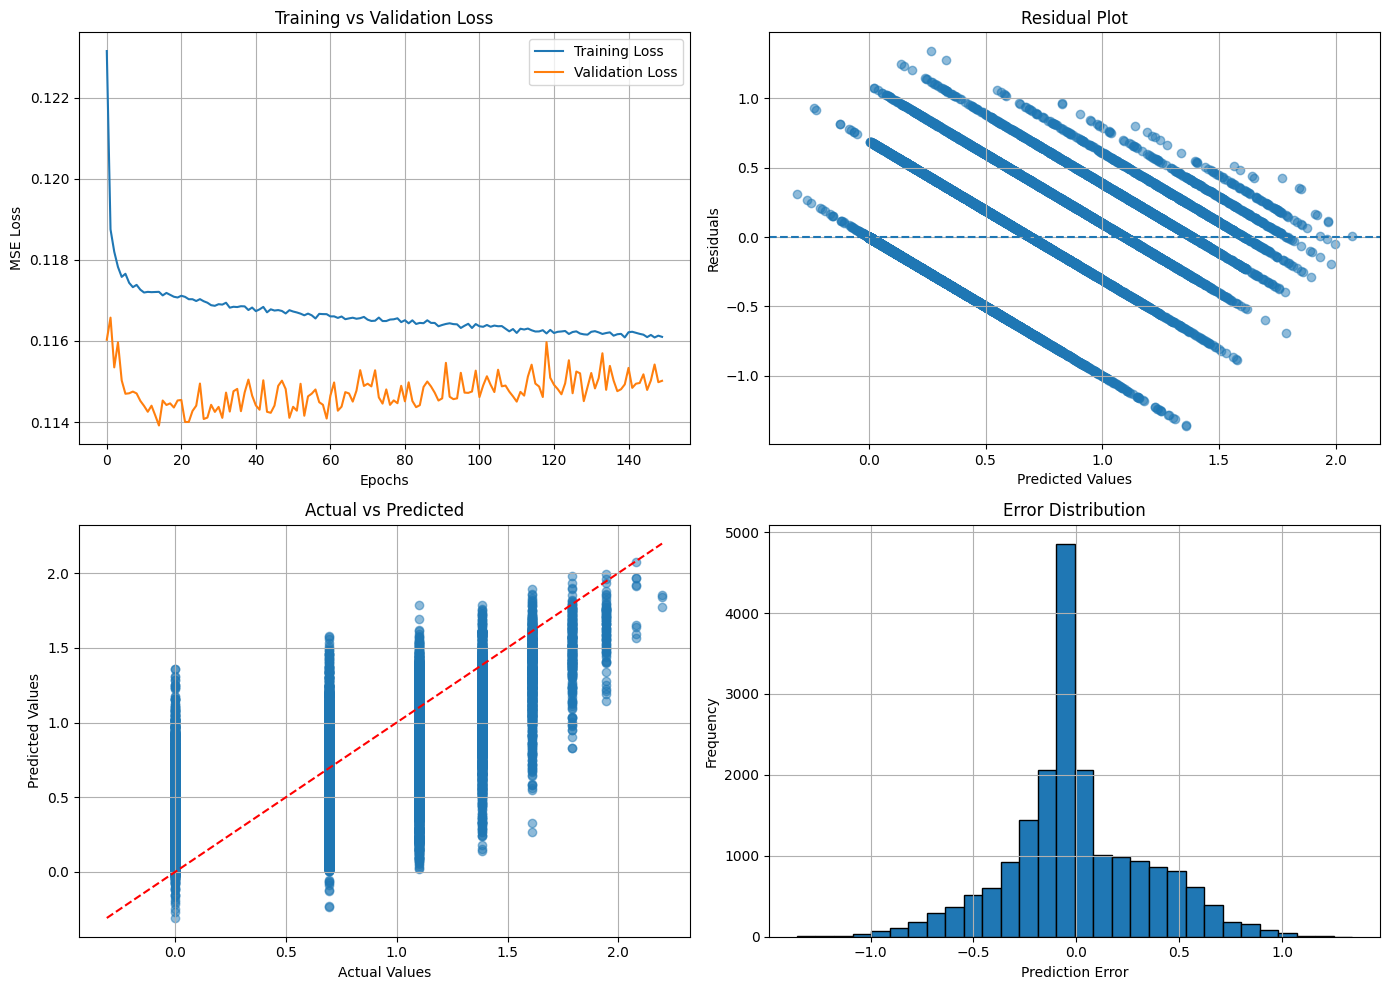

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

y_pred_20 = model_80.predict(X_test_20_scaled).flatten()
errors = y_test_20 - y_pred_20
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Loss Curve
axes[0, 0].plot(history_80.history['loss'], label='Training Loss')
axes[0, 0].plot(history_80.history['val_loss'], label='Validation Loss')
axes[0, 0].set_title('Training vs Validation Loss')
axes[0, 0].set_xlabel('Epochs')
axes[0, 0].set_ylabel('MSE Loss')
axes[0, 0].legend()
axes[0, 0].grid(True)

# 2. Residual Plot
axes[0, 1].scatter(y_pred_20, errors, alpha=0.5)
axes[0, 1].axhline(y=0, linestyle='--')
axes[0, 1].set_title('Residual Plot')
axes[0, 1].set_xlabel('Predicted Values')
axes[0, 1].set_ylabel('Residuals')
axes[0, 1].grid(True)

# 3. Actual vs Predicted
axes[1, 0].scatter(y_test_20, y_pred_20, alpha=0.5)

min_val = min(y_test_20.min(), y_pred_20.min())
max_val = max(y_test_20.max(), y_pred_20.max())

axes[1, 0].plot([min_val, max_val], [min_val, max_val], 'r--')
axes[1, 0].set_title('Actual vs Predicted')
axes[1, 0].set_xlabel('Actual Values')
axes[1, 0].set_ylabel('Predicted Values')
axes[1, 0].grid(True)

# 4. Error Distribution
axes[1, 1].hist(errors, bins=30, edgecolor='black')
axes[1, 1].set_title('Error Distribution')
axes[1, 1].set_xlabel('Prediction Error')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()

#### Architecture 2:

In [ ]:
X_train_80, X_test_20, y_train_80, y_test_20 = train_test_split(X, y, test_size=0.20, random_state=42)

scaler_80 = StandardScaler()
X_train_80_scaled = scaler_80.fit_transform(X_train_80)
X_test_20_scaled = scaler_80.transform(X_test_20)

model = Sequential([
    Dense(32, activation='relu', input_shape=(X_train_80_scaled.shape[1],)),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='mse'
)

history = model.fit(
    X_train_80_scaled, y_train_80,
    validation_data=(X_test_20_scaled, y_test_20),
    epochs=100,
    batch_size=32,
    verbose=0
)

y_pred_20 = model.predict(X_test_20_scaled)
print(f"80/20 MSE: {mean_squared_error(y_test_20, y_pred_20):.4f}")
print(f"80/20 R-squared: {r2_score(y_test_20, y_pred_20):.4f}")

614/614 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
80/20 MSE: 0.1155
80/20 R-squared: 0.6513


In [ ]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_80_scaled.shape[1],)),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

history = model.fit(
    X_train_80_scaled, y_train_80,
    validation_data=(X_test_20_scaled, y_test_20),
    epochs=300,
    batch_size=64,
    verbose=0
)
y_pred_20 = model.predict(X_test_20_scaled)
print(f"80/20 MSE: {mean_squared_error(y_test_20, y_pred_20):.4f}")
print(f"80/20 R-squared: {r2_score(y_test_20, y_pred_20):.4f}")

614/614 ━━━━━━━━━━━━━━━━━━━━ 1s 886us/step
80/20 MSE: 0.1191
80/20 R-squared: 0.6405


In [ ]:
model = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_80_scaled.shape[1],)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss='mse'
)

history = model.fit(
    X_train_80_scaled, y_train_80,
    validation_data=(X_test_20_scaled, y_test_20),
    epochs=400,
    batch_size=64,
    verbose=0
)
y_pred_20 = model.predict(X_test_20_scaled)
print(f"80/20 MSE: {mean_squared_error(y_test_20, y_pred_20):.4f}")
print(f"80/20 R-squared: {r2_score(y_test_20, y_pred_20):.4f}")

614/614 ━━━━━━━━━━━━━━━━━━━━ 1s 979us/step
80/20 MSE: 0.1306
80/20 R-squared: 0.6059


In [ ]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_80_scaled.shape[1],)),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

history = model.fit(
    X_train_80_scaled, y_train_80,
    validation_data=(X_test_20_scaled, y_test_20),
    epochs=500,
    batch_size=32,
    verbose=0
)
y_pred_20 = model.predict(X_test_20_scaled)
print(f"80/20 MSE: {mean_squared_error(y_test_20, y_pred_20):.4f}")
print(f"80/20 R-squared: {r2_score(y_test_20, y_pred_20):.4f}")

614/614 ━━━━━━━━━━━━━━━━━━━━ 1s 870us/step
80/20 MSE: 0.1229
80/20 R-squared: 0.6290


In [ ]:
model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train_80_scaled.shape[1],)),
    BatchNormalization(),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse'
)

history = model.fit(
    X_train_80_scaled, y_train_80,
    validation_data=(X_test_20_scaled, y_test_20),
    epochs=600,
    batch_size=64,
    verbose=0
)
y_pred_20 = model.predict(X_test_20_scaled)
print(f"80/20 MSE: {mean_squared_error(y_test_20, y_pred_20):.4f}")
print(f"80/20 R-squared: {r2_score(y_test_20, y_pred_20):.4f}")

614/614 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  
80/20 MSE: 0.1172
80/20 R-squared: 0.6461


In [ ]:
model = Sequential([
    Dense(128, activation='tanh', input_shape=(X_train_80_scaled.shape[1],)),
    Dense(64, activation='tanh'),
    Dense(32, activation='tanh'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='mse'
)

history = model.fit(
    X_train_80_scaled, y_train_80,
    validation_data=(X_test_20_scaled, y_test_20),
    epochs=700,
    batch_size=128,
    verbose=0
)
y_pred_20 = model.predict(X_test_20_scaled)
print(f"80/20 MSE: {mean_squared_error(y_test_20, y_pred_20):.4f}")
print(f"80/20 R-squared: {r2_score(y_test_20, y_pred_20):.4f}")

614/614 ━━━━━━━━━━━━━━━━━━━━ 1s 921us/step
80/20 MSE: 0.1143
80/20 R-squared: 0.6551


In [ ]:
model = Sequential([
    Dense(128, activation='elu', input_shape=(X_train_80_scaled.shape[1],)),
    Dense(64, activation='elu'),
    Dense(32, activation='elu'),
    Dense(1)
])

model.compile(
    optimizer=Adam(learning_rate=0.002),
    loss='mse'
)

history = model.fit(
    X_train_80_scaled, y_train_80,
    validation_data=(X_test_20_scaled, y_test_20),
    epochs=800,
    batch_size=32,
    verbose=0
)
y_pred_20 = model.predict(X_test_20_scaled)
print(f"80/20 MSE: {mean_squared_error(y_test_20, y_pred_20):.4f}")
print(f"80/20 R-squared: {r2_score(y_test_20, y_pred_20):.4f}")

614/614 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
80/20 MSE: 0.1147
80/20 R-squared: 0.6539


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define the parameters to search
param_grid_knn = {
    'n_neighbors': [3, 7, 11],
    'weights': ['uniform', 'distance'],
    'p': [1, 2]  # 1 is Manhattan distance, 2 is Euclidean distance
}

# 2. Initialize GridSearchCV
grid_knn = GridSearchCV(
    KNeighborsRegressor(),
    param_grid_knn,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

# 3. Fit to the training data
grid_knn.fit(X_train, y_train)

# 4. Evaluate the best model
best_knn = grid_knn.best_estimator_
y_pred_knn = best_knn.predict(X_test)

print("--- Tuned KNN ---")
print("Best Parameters:", grid_knn.best_params_)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_knn))
print("R-squared:", r2_score(y_test, y_pred_knn))

--- Tuned KNN ---
Best Parameters: {'n_neighbors': 11, 'p': 2, 'weights': 'uniform'}
Mean Squared Error: 0.12848493298665103
R-squared: 0.6110185816258473


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Define the parameters to search
param_grid_rf = {
    'n_estimators': [50, 100],
    'max_depth': [None, 10, 20],
}

# 2. Initialize GridSearchCV
grid_rf = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid_rf,
    cv=5,
    scoring='r2',
    n_jobs=-1
)

# 3. Fit to the training data
grid_rf.fit(X_train, y_train)

# 4. Evaluate the best model
best_rf = grid_rf.best_estimator_
y_pred_rf = best_rf.predict(X_test)

print("--- Tuned Random Forest ---")
print("Best Parameters:", grid_rf.best_params_)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_rf))
print("R-squared:", r2_score(y_test, y_pred_rf))

--- Tuned Random Forest ---
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Mean Squared Error: 0.11798405997371605
R-squared: 0.6428094257644569


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
dt = DecisionTreeRegressor(random_state=42)

dt_params = {
    'criterion': ['squared_error', 'absolute_error'],
    'max_depth': [None, 3, 5, 7],
}

dt_grid = GridSearchCV(
    estimator=dt,
    param_grid=dt_params,
    cv=5,
    scoring='r2',
    n_jobs=-1
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
dt_grid.fit(X_train, y_train)

print("Best Parameters:", dt_grid.best_params_)
print("Best CV R2:", dt_grid.best_score_)
dt_best = dt_grid.best_estimator_

y_pred_dt = dt_best.predict(X_test)

print("Decision Tree Regression")
print("R2 Score:", r2_score(y_test, y_pred_dt))
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))

In [ ]:
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
svr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svr', SVR())
])

svr_params = [
    {
        'svr__kernel': ['linear'],
        'svr__C': [0.1, 1, 10]
    },
    {
        'svr__kernel': ['poly'],
        'svr__C': [0.1, 1, 10],
    }
]

svr_grid = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_params,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

svr_grid.fit(X_train, y_train)

print("Best Parameters:", svr_grid.best_params_)
print("Best CV R2:", svr_grid.best_score_)

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV

# 1. Initialize XGBoost Regressor
xgb = XGBRegressor(random_state=42)

# 2. Define the hyperparameter grid for XGBoost
xgb_params = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
}

# 3. Set up the GridSearchCV
xgb_grid = GridSearchCV(
    estimator=xgb,
    param_grid=xgb_params,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

# 4. Fit the model
xgb_grid.fit(X_train, y_train)

# 5. Print results
print("Best Parameters:", xgb_grid.best_params_)
print("Best CV R2:", xgb_grid.best_score_)